# Live visual-language lenses: raw image to fresh plots

This walkthrough loads a pretrained **SmolVLM-500M**, reads raw GQA/COCO examples,
constructs native image prompts, computes readouts, fits fresh Tuned Lens translators,
and performs Patchscope replacement. Raw images/manifests under `demos/assets`
are dataset inputs; no precomputed measurements, calibration weights or figures
are loaded. Every preparation, training, method and plotting call is visible.

Install `pip install "vlmprobe[transformers,visualization,notebooks]"` and open this
notebook from the repository. The checkpoint downloads if absent. A GPU is
recommended; CPU uses float32 and is slower. Exact Jacobian and dense per-head
training are shown in the [text walkthrough](lens_comparison_demo.ipynb), where
memory and computation are easier to inspect.


## Runtime setup

Run the setup cell first. In Google Colab it obtains a Git checkout and installs
the notebook dependencies; local execution keeps the existing environment.
Choose a GPU runtime when required by the walkthrough.

Optional environment settings: VLM_PROBING_REPOSITORY (default
ubc-tea/vlm-probe), VLM_PROBING_REF (default main), and
VLM_PROBING_COLAB_DIR (default /content/vlm-probe). The repository and ref
select a new checkout. An existing vlmprobe checkout is reused at its current
commit without discarding local changes. The cell prints that commit.

All input construction, calibration, probing and plotting remain visible in
the analysis cells below. Restart the runtime only if the setup cell reports
that an already imported package or checkout has changed.


In [ ]:
#@title Runtime setup (Colab only; expand to inspect)
# Environment setup only; the analysis workflow is visible in the cells below.
import os as _nb_setup_os
import sys as _nb_setup_sys

_nb_setup_in_colab = (
    "google.colab" in _nb_setup_sys.modules
    or bool(_nb_setup_os.environ.get("COLAB_RELEASE_TAG"))
)
if _nb_setup_in_colab:
    import hashlib as _nb_setup_hashlib
    import importlib as _nb_setup_importlib
    import importlib.metadata as _nb_setup_metadata
    from pathlib import Path as _NBSetupPath
    import re as _nb_setup_re
    import subprocess as _nb_setup_subprocess

    _nb_setup_repo = _nb_setup_os.environ.get(
        "VLM_PROBING_REPOSITORY", "ubc-tea/vlm-probe"
    )
    _nb_setup_ref = _nb_setup_os.environ.get("VLM_PROBING_REF", "main")
    if not _nb_setup_re.fullmatch(
        r"[A-Za-z0-9][A-Za-z0-9-]*/[A-Za-z0-9][A-Za-z0-9_.-]*",
        _nb_setup_repo,
    ):
        raise ValueError("VLM_PROBING_REPOSITORY must be a GitHub owner/repository.")
    if not _nb_setup_ref or _nb_setup_ref.startswith("-") or any(
        character.isspace() for character in _nb_setup_ref
    ):
        raise ValueError("VLM_PROBING_REF must be a nonempty Git ref or commit SHA.")
    _nb_setup_checkout = _NBSetupPath(
        _nb_setup_os.environ.get("VLM_PROBING_COLAB_DIR", "/content/vlm-probe")
    ).expanduser().resolve()
    _nb_setup_existing = _nb_setup_checkout.exists()
    if not _nb_setup_existing:
        _nb_setup_checkout.parent.mkdir(parents=True, exist_ok=True)
        _nb_setup_subprocess.check_call([
            "git", "clone", "--depth=1", "--no-checkout",
            "https://github.com/" + _nb_setup_repo + ".git",
            str(_nb_setup_checkout),
        ])
        _nb_setup_subprocess.check_call([
            "git", "-C", str(_nb_setup_checkout), "fetch",
            "--depth=1", "origin", _nb_setup_ref,
        ])
        _nb_setup_subprocess.check_call([
            "git", "-C", str(_nb_setup_checkout),
            "checkout", "--detach", "FETCH_HEAD",
        ])

    # Validate before changing directories or installing anything. In
    # particular, never reset, clean or overwrite an existing user directory.
    _nb_setup_pyproject = _nb_setup_checkout / "pyproject.toml"
    _nb_setup_init = _nb_setup_checkout / "src/vlm_probing/__init__.py"
    if (
        not _nb_setup_checkout.is_dir()
        or not _nb_setup_pyproject.is_file()
        or not _nb_setup_init.is_file()
        or not (_nb_setup_checkout / "src/vlmprobe/__init__.py").is_file()
        or not (_nb_setup_checkout / "src/vlm_probing/prober.py").is_file()
        or not (_nb_setup_checkout / "demos").is_dir()
    ):
        raise RuntimeError(
            "The setup directory is not a vlmprobe checkout. It was left "
            "untouched. Set VLM_PROBING_COLAB_DIR to a new directory."
        )
    _nb_setup_project_section = _nb_setup_re.search(
        r"(?ms)^\[project\][^\n]*\n(.*?)(?=^\[|\Z)",
        _nb_setup_pyproject.read_text(),
    )
    if not _nb_setup_project_section or not _nb_setup_re.search(
        r"""(?m)^name\s*=\s*["']vlmprobe["']\s*$""",
        _nb_setup_project_section.group(1),
    ):
        raise RuntimeError(
            "The existing directory declares a different project; it was "
            "left untouched. Choose another VLM_PROBING_COLAB_DIR."
        )

    def _nb_setup_git(*arguments):
        return _nb_setup_subprocess.check_output(
            ["git", "-C", str(_nb_setup_checkout), *arguments], text=True
        ).strip()

    try:
        _nb_setup_git_root = _NBSetupPath(
            _nb_setup_git("rev-parse", "--show-toplevel")
        ).resolve()
        _nb_setup_sha = _nb_setup_git("rev-parse", "HEAD")
        _nb_setup_dirty = bool(_nb_setup_git("status", "--porcelain"))
    except _nb_setup_subprocess.CalledProcessError as _nb_setup_error:
        raise RuntimeError(
            "The existing vlmprobe directory is not a readable Git checkout; "
            "it was not reset or replaced. Choose another setup directory."
        ) from _nb_setup_error
    if _nb_setup_git_root != _nb_setup_checkout:
        raise RuntimeError(
            "The setup directory is inside another Git project, not the "
            "vlmprobe checkout root. Choose another setup directory."
        )
    if _nb_setup_existing:
        print(
            "Reusing the existing vlmprobe checkout; repository/ref settings "
            "apply only to a new checkout."
        )
    print("vlmprobe checkout:", _nb_setup_checkout, "@", _nb_setup_sha)
    if _nb_setup_dirty:
        print("Local checkout changes are preserved.")

    _nb_setup_distributions = {
        "vlmprobe": "vlmprobe",
        "vlm_probing": "vlmprobe",
        "torch": "torch",
        "transformers": "transformers",
        "numpy": "numpy",
        "PIL": "Pillow",
        "safetensors": "safetensors",
        "huggingface_hub": "huggingface-hub",
    }
    _nb_setup_loaded = {
        name: (
            getattr(_nb_setup_sys.modules[name], "__version__", None),
            getattr(_nb_setup_sys.modules[name], "__file__", None),
        )
        for name in _nb_setup_distributions
        if name in _nb_setup_sys.modules
    }
    _nb_setup_extras = "transformers,visualization,sae,evaluation"
    _nb_setup_signature = (
        str(_nb_setup_checkout), _nb_setup_sha, _nb_setup_sys.executable,
        _nb_setup_hashlib.sha256(_nb_setup_pyproject.read_bytes()).hexdigest(),
        _nb_setup_extras,
    )
    _nb_setup_previous = globals().get("_vlmprobe_colab_setup_state", {})
    if not isinstance(_nb_setup_previous, dict):
        _nb_setup_previous = {}
    _nb_setup_os.chdir(_nb_setup_checkout)
    if _nb_setup_previous.get("signature") != _nb_setup_signature:
        _nb_setup_subprocess.check_call([
            _nb_setup_sys.executable, "-m", "pip", "install", "-e",
            str(_nb_setup_checkout) + "[" + _nb_setup_extras + "]",
        ])
        _vlmprobe_colab_setup_state = {"signature": _nb_setup_signature}
    else:
        print("This runtime already prepared the same checkout and dependencies.")
    _nb_setup_source_path = str(_nb_setup_checkout / "src")
    if _nb_setup_source_path not in _nb_setup_sys.path:
        _nb_setup_sys.path.insert(0, _nb_setup_source_path)
    _nb_setup_importlib.invalidate_caches()

    _nb_setup_restart = []
    if (
        _nb_setup_previous.get("signature")
        and _nb_setup_previous["signature"] != _nb_setup_signature
        and any(name in _nb_setup_loaded for name in ("vlmprobe", "vlm_probing"))
    ):
        _nb_setup_restart.append(
            "the checkout or installation changed after vlmprobe was imported"
        )
    for _nb_setup_name, (_nb_setup_loaded_version, _nb_setup_origin) in _nb_setup_loaded.items():
        if _nb_setup_name in ("vlmprobe", "vlm_probing") and _nb_setup_origin:
            if not _NBSetupPath(_nb_setup_origin).resolve().is_relative_to(
                _nb_setup_checkout / "src"
            ):
                _nb_setup_restart.append(_nb_setup_name + " was imported from another checkout")
        if _nb_setup_loaded_version is not None:
            try:
                _nb_setup_installed_version = _nb_setup_metadata.version(
                    _nb_setup_distributions[_nb_setup_name]
                )
            except _nb_setup_metadata.PackageNotFoundError:
                continue
            if str(_nb_setup_loaded_version) != _nb_setup_installed_version:
                _nb_setup_restart.append(
                    _nb_setup_name + " " + str(_nb_setup_loaded_version)
                    + " is loaded; installed version is " + _nb_setup_installed_version
                )
    if _nb_setup_restart:
        raise RuntimeError(
            "Setup completed, but this runtime already imported an older or "
            "different package. Restart the Colab runtime, rerun this setup "
            "cell, and then run the analysis cells. Details: "
            + "; ".join(_nb_setup_restart)
        )
    print("Setup complete. Run the analysis cells below.")
else:
    print("Local runtime: using the existing checkout and environment.")


In [1]:
%matplotlib inline
import hashlib
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from PIL import Image
from transformers import AutoModelForImageTextToText, AutoProcessor
from vlmprobe import Prober
from vlmprobe.visualization import plot_input, plot_lens_heatmap

ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
            if (p / "demos/assets/gqa_samples.json").is_file())
RAW = ROOT / "demos/assets"
OUT = Path(os.environ.get("VLM_PROBING_OUTPUT", str(ROOT / "outputs/live-vlm-lenses")))
OUT.mkdir(parents=True, exist_ok=True)
MODEL_ID = os.environ.get("VLM_PROBING_MODEL", "HuggingFaceTB/SmolVLM-500M-Instruct")
DEVICE = os.environ.get("VLM_PROBING_DEVICE", "cuda:0" if torch.cuda.is_available() else "cpu")
torch.manual_seed(0)
model = AutoModelForImageTextToText.from_pretrained(
    MODEL_ID, dtype=torch.float32, attn_implementation="eager",
).to(DEVICE).eval()
processor = AutoProcessor.from_pretrained(MODEL_ID)
tokenizer = processor.tokenizer
probe = Prober(model, processor)
capabilities = probe.describe()
print({name: info["sites"] for name, info in capabilities["methods"].items() if info["available"]})


Loading weights:   0%|          | 0/489 [00:00<?, ?it/s]

{'lens.logit': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31], 'lens.tuned': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31], 'lens.jacobian': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31], 'lens.embed': ['embeddings'], 'lens.attention': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31], 'lens.patchscope': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31], 'attention.profile': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31], 'attention.rollout': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31], 'atte

## 1. Read the raw dataset record and construct the prompt

We verify the original GQA image checksum, display the question and annotated answer, then let the native processor perform image crops and token expansion.

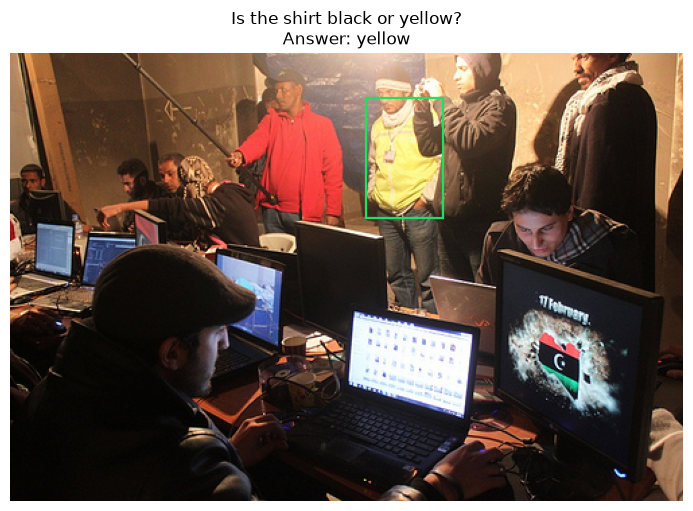

answer subwords: ["' yellow'"]


In [2]:
gqa_records = json.loads((RAW / "gqa_samples.json").read_text())
coco_records = json.loads((RAW / "coco_samples.json").read_text())["samples"]
showcase = gqa_records[0]
image_path = RAW / "images" / showcase["image_path"]
assert hashlib.sha256(image_path.read_bytes()).hexdigest() == showcase["image_sha256"]
image = Image.open(image_path).convert("RGB")
question, annotated_answer = showcase["question"], showcase["answer"]

def prepare_vlm(image, text):
    messages = [{"role": "user", "content": [
        {"type": "image"}, {"type": "text", "text": text},
    ]}]
    prompt = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    return probe.prepare(prompt=prompt, image=image, device=DEVICE)

inputs = prepare_vlm(image, question)
ax = plot_input(image, prompt=question, answer=annotated_answer,
                bounding_boxes=[showcase["bbox_xywh"]])
plt.show()
answer_ids = tokenizer.encode(" " + annotated_answer, add_special_tokens=False)
# The rank plot explicitly tracks the first subword only, not a whole answer.
answer_id = answer_ids[0]
print("answer subwords:", [repr(tokenizer.decode([i])) for i in answer_ids])


## 2. Run Logit Lens and plot a fixed target subword

Only supported residual layers are selected from `describe()`. Multilingual or partial token annotations are shown exactly as decoded; they are not generated answer text.

Rank plots show measured token ranks. Inspect the printed native token IDs and decoded strings for lexical details; arbitrary multilingual fragments are not forced into plot-cell annotations.


logits / coordinates: torch.Size([3, 45, 49280]) torch.Size([45, 2])


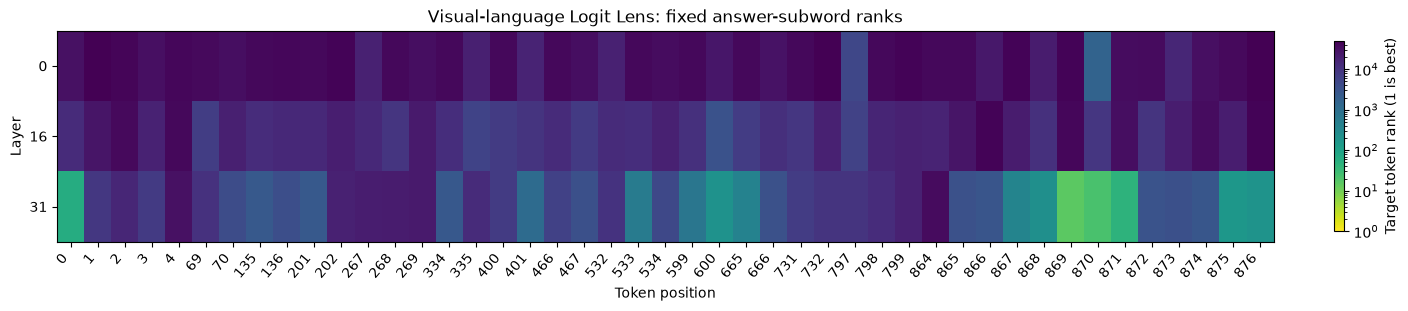

In [3]:
available = capabilities["methods"]["lens.logit"]["sites"]
layers = [available[0], available[len(available) // 2], available[-1]]
logit = probe.lens.logit(layers=layers, tokens="text").run(inputs)
print("logits / coordinates:", logit.tensors["logits"].shape, logit.tensors["positions"].shape)
ax = plot_lens_heatmap(logit, target_token_id=answer_id,                        title="Visual-language Logit Lens: fixed answer-subword ranks")
ax.figure.savefig(OUT / "vlm-logit.png", dpi=160, bbox_inches="tight")
plt.show()


## 3. Run EmbedLens on the projected visual-token input

This is one decoder-input embedding site, not a decoder-layer sweep. Cosine nearest neighbors are associations rather than token probabilities. Multi-crop geometry is not guessed; columns below retain token coordinates.

visual neighbors: torch.Size([1, 832, 5])
[0, 5] [("'<|im_end|>'", 0.378), ("'<|im_start|>'", 0.378), ("'MetaInfoClass'", 0.374), ("'deliverystream'", 0.374), ("'\\x00'", 0.374)]
[0, 6] [('"|\')\'"', 0.414), ("'<|im_start|>'", 0.414), ("'<|im_end|>'", 0.411), ("'\\x00'", 0.408), ("'MetaInfoClass'", 0.408)]
[0, 7] [("'<|im_end|>'", 0.442), ("'<|im_start|>'", 0.442), ('"|\')\'"', 0.439), ("'\\x00'", 0.437), ("'MetaInfoClass'", 0.436)]
[0, 8] [("'<|im_start|>'", 0.421), ("'<|im_end|>'", 0.421), ('"|\')\'"', 0.417), ("'\\x00'", 0.416), ("'MetaInfoClass'", 0.416)]
[0, 9] [("'<|im_start|>'", 0.417), ("'<|im_end|>'", 0.415), ("'\\x00'", 0.414), ("'MetaInfoClass'", 0.412), ("'PlaneProtection'", 0.412)]
[0, 10] [('"|\')\'"', 0.338), ("'<|im_start|>'", 0.337), ("'swigfaiss'", 0.336), ("'\\x00'", 0.336), ("'<|im_end|>'", 0.335)]
[0, 11] [("'<|im_end|>'", 0.43), ("'<|im_start|>'", 0.43), ("'\\x00'", 0.428), ('"|\')\'"', 0.427), ("'MetaInfoClass'", 0.426)]
[0, 12] [("'<|im_end|>'", 0.339), ("'<|im_

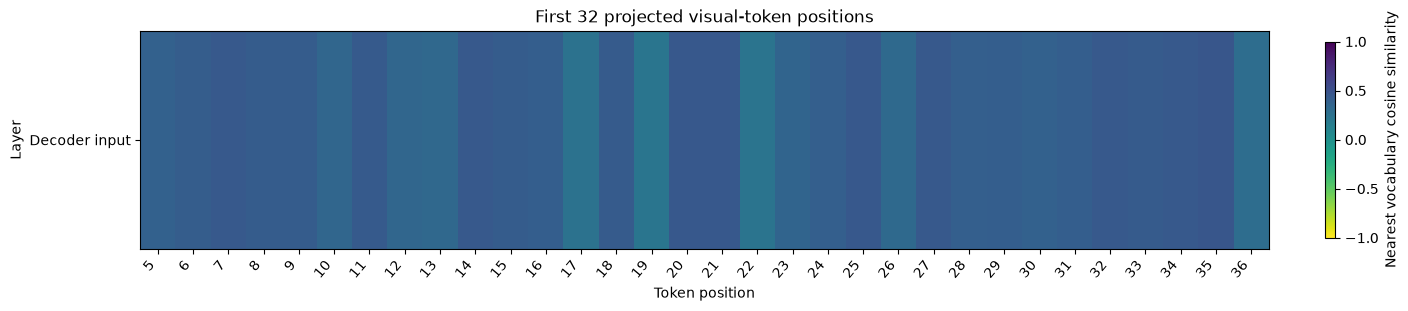

In [4]:
embed = probe.lens.embed(tokens="visual").run(inputs, top_k=5, vocabulary_chunk_size=4096)
print("visual neighbors:", embed.tensors["token_ids"].shape)
for position, ids, scores in zip(embed.tensors["positions"][:8], embed.tensors["token_ids"][0, :8], embed.tensors["similarities"][0, :8]):
    print(position.tolist(), [(repr(tokenizer.decode([int(i)])), round(float(s), 3)) for i, s in zip(ids, scores)])
count = min(32, len(embed.tensors["positions"]))
ax = plot_lens_heatmap(embed.tensors["similarities"][0, :count, 0][None],
                       value_kind="logit", log_scale=False, vmin=-1, vmax=1,
                       layer_labels=["Decoder input"],
                       token_labels=embed.tensors["positions"][:count, 1].tolist(),
                       value_label="Nearest vocabulary cosine similarity",
                       title="First 32 projected visual-token positions")
ax.figure.savefig(OUT / "vlm-embed.png", dpi=160, bbox_inches="tight")
plt.show()


## 4. Train, validate, save and restore a Tuned Lens

The training and validation COCO images are distinct from each other and from the GQA showcase. With just one image per split, this demonstrates the whole protocol but cannot establish calibration quality. The base model stays frozen.

{"method": "tuned_lens", "epoch": 1, "train_kl": 7.467871189117432, "train_positions": 1, "optimizer_steps": 1, "validation": {"kl": 5.77614164352417, "top1_agreement": 0.0, "positions": 1}, "elapsed_seconds": 0.09846316400216892, "best_validation_kl": 5.77614164352417}


{"method": "tuned_lens", "epoch": 2, "train_kl": 4.433225631713867, "train_positions": 1, "optimizer_steps": 1, "validation": {"kl": 4.64179801940918, "top1_agreement": 1.0, "positions": 1}, "elapsed_seconds": 0.2985316389822401, "best_validation_kl": 4.64179801940918}


{"method": "tuned_lens", "epoch": 1, "train_kl": 11.71535873413086, "train_positions": 1, "optimizer_steps": 1, "validation": {"kl": 12.922759056091309, "top1_agreement": 0.0, "positions": 1}, "elapsed_seconds": 0.02394471998559311, "best_validation_kl": 10.958030700683594}


{"method": "tuned_lens", "epoch": 2, "train_kl": 11.504931449890137, "train_positions": 1, "optimizer_steps": 1, "validation": {"kl": 5.298922061920166, "top1_agreement": 0.0, "positions": 1}, "elapsed_seconds": 0.20330137299606577, "best_validation_kl": 5.298922061920166}


{"method": "tuned_lens", "epoch": 1, "train_kl": -1.804960447771009e-08, "train_positions": 1, "optimizer_steps": 1, "validation": {"kl": 10.493000984191895, "top1_agreement": 1.0, "positions": 1}, "elapsed_seconds": 0.022188642993569374, "best_validation_kl": -1.2580130714923143e-08}


{"method": "tuned_lens", "epoch": 2, "train_kl": 12.017065048217773, "train_positions": 1, "optimizer_steps": 1, "validation": {"kl": 9.238367080688477, "top1_agreement": 0.0, "positions": 1}, "elapsed_seconds": 0.16883258600137196, "best_validation_kl": -1.2580130714923143e-08}


0 {'kl': 7.013924598693848, 'top1_agreement': 0.0, 'positions': 1} 4.64179801940918
16 {'kl': 10.958030700683594, 'top1_agreement': 0.0, 'positions': 1} 5.298922061920166
31 {'kl': -1.2580130714923143e-08, 'top1_agreement': 1.0, 'positions': 1} -1.2580130714923143e-08


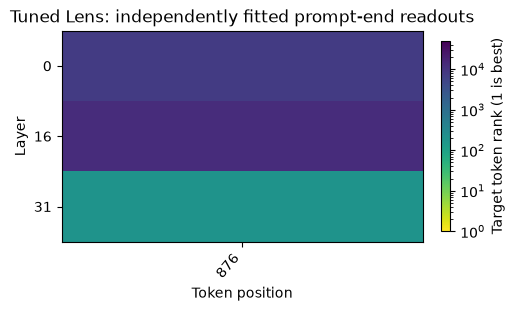

In [5]:
# One COCO image for training, another for validation; GQA showcase is separate.
# This is the entire tiny split. It is an engineering demonstration, not enough
# data to claim a well-calibrated VLM lens. Production: split/scale by image ID.
assert showcase["image_id"] not in {str(r["image_id"]) for r in coco_records}
assert coco_records[0]["image_id"] != coco_records[1]["image_id"]
train_inputs, validation_inputs = [], []
for record, destination in [(coco_records[0], train_inputs), (coco_records[1], validation_inputs)]:
    path = RAW / "images" / record["file"]
    assert hashlib.sha256(path.read_bytes()).hexdigest() == record["sha256"]
    destination.append(prepare_vlm(Image.open(path).convert("RGB"), "Describe the image in one sentence."))
split_hash = hashlib.sha256(json.dumps([coco_records[0]["image_id"], coco_records[1]["image_id"]]).encode()).hexdigest()
binding = {"model_id": MODEL_ID + "@" + str(getattr(model.config, "_commit_hash", None) or "local-checkpoint"),
           "tokenizer_id": tokenizer.name_or_path, "readout_id": "native-final-norm+lm_head",
           "calibration_id": "distinct-coco-images-sha256:" + split_hash}
# Prompt-end fitting keeps the example small. Caption-position training requires
# an explicit caption prediction-position mask; see docs/TRAINING.md.
tuned_method = probe.lens.tuned(layers=layers, tokens="last_prompt", binding=binding)
tuned_method.fit_batches(train_inputs, validation_inputs, OUT / "tuned-artifact",
                         batch_size=1, epochs=2, lr=1e-3, patience=2, seed=0, resume=False)
tuned = tuned_method.run(inputs)
for layer, history in tuned_method.training_history.items():
    print(layer, history["initial_validation"], history["best_validation_kl"])
ax = plot_lens_heatmap(tuned, target_token_id=answer_id,                        title="Tuned Lens: independently fitted prompt-end readouts")
ax.figure.savefig(OUT / "vlm-tuned.png", dpi=160, bbox_inches="tight")
plt.show()
restored = probe.lens.tuned(layers=layers, tokens="last_prompt", binding=binding).load(OUT / "tuned-artifact")


## 5. Transfer the source state into an explicitly constructed target

Patchscope uses the same model. The displayed value is a target next-subword readout after replacement, not autoregressive text generation or a natural-language explanation.

full target logits: torch.Size([3, 1, 880, 49280])


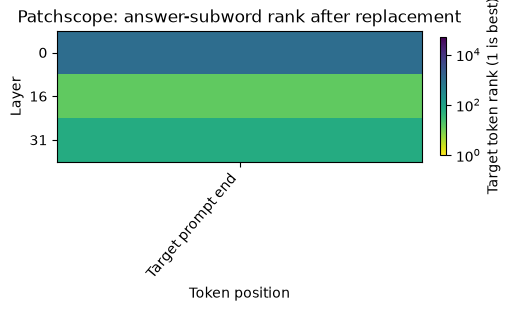

In [6]:
# An explicit copy-style target prompt in the same VLM, with the same raw image.
target_inputs = prepare_vlm(image, "Red: Red. Blue: Blue. Yellow:")
# Public result positions preserve expanded coordinates after visual merging.
source_position = int(probe.lens.logit(layers=[layers[-1]]).run(inputs).tensors["positions"][0, 1])
target_position = int(probe.lens.logit(layers=[layers[-1]]).run(target_inputs).tensors["positions"][0, 1])
scope = probe.lens.patchscope(layers=layers, source_position=source_position,
                              target_layer=layers[0], target_position=target_position)
patched = scope.run(inputs, target_inputs=target_inputs)
print("full target logits:", patched.tensors["logits"].shape)
ax = plot_lens_heatmap(patched.tensors["logits"][:, 0, -1:, :],
                       target_token_id=answer_id, layer_labels=layers,
                       token_labels=["Target prompt end"],                        title="Patchscope: answer-subword rank after replacement")
ax.figure.savefig(OUT / "vlm-patchscope.png", dpi=160, bbox_inches="tight")
plt.show()


## Extend this analysis

Use independent, image-disjoint calibration/validation corpora before drawing
conclusions about fitted lenses. For caption-position fitting and artifact
identity, follow [the training protocol](../docs/TRAINING.md). To use a different
VLM, replace native model/input preparation using its [model guide](../docs/models/README.md),
then keep the same supported method calls. Layer support is reported by
`probe.describe()`; head support can differ from residual support.

Raw GQA metadata cites the [Cross-modal Information Flow author subset](https://github.com/FightingFighting/cross-modal-information-flow-in-MLLM/tree/main/datasets);
raw COCO/POPE provenance is retained in `demos/assets/coco_samples.json`.
